In [1]:
import sys
sys.path.insert(0, "../")

import numpy as np
import matplotlib.pyplot as plt
from src.FunctionsGenerator import FunctionsGenerator
from src.Heat1DCrankNicolson import Heat1DCrankNicolson

plt.style.use("../styles/plots.mplstyle")
np.random.seed(42)

In [2]:
# Parametri simulazione
L = 1
Tf = 100
nt = 1000
D = 0.05
wanted_r = 0.5
h = 1

# Inizializza solver
solver = Heat1DCrankNicolson(L,Tf,nt,D,h,wanted_r=wanted_r)
solver.info()

_, n_eff = solver.diffusion_time()

from src.TikhonovHandler import TikhonovHandler, reconstruction_error_plot
th = TikhonovHandler(solver)


-----------------------------Solver info------------------------------

Diffusion time:                                               2.00e+01
dx:                                                           1.00e-01
dt:                                                           1.00e-01
nt:                                                               1000
nx:                                                                 11
r:                                                            5.00e-01
h:                                                            1.00e+00


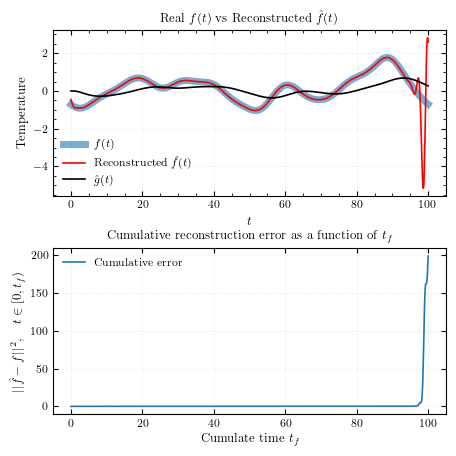

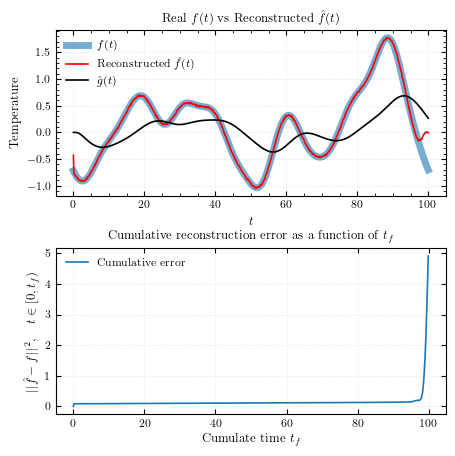

In [3]:
# Testing reconstruction without any sensor distorsion

f_generator = FunctionsGenerator(solver.t_array, l=5)

f = f_generator.generate_from_white_noise(42)
g = solver.solve(f)[solver.nx-1,:]

f_reconstructed = th.regularize(g, lambda_reg=1e-3, regularization_type_="closed", maxiter=100)

_, _ ,_ = reconstruction_error_plot(f,g,f_reconstructed,solver.t_array)

f_reconstructed = th.regularize(g, lambda_reg=1e-3, regularization_type_="fft", maxiter=100)

_, _ ,_ = reconstruction_error_plot(f,g,f_reconstructed,solver.t_array)

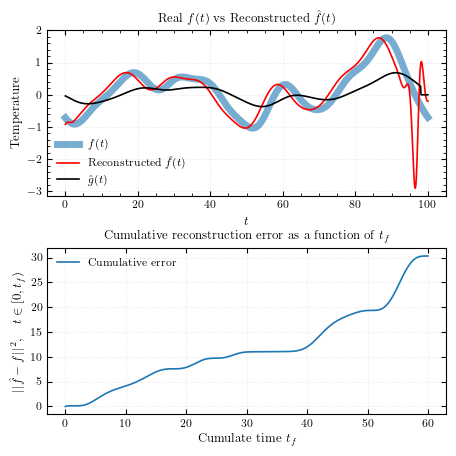

In [4]:
# Testing reconstruction with sensor delay

f = f_generator.generate_from_white_noise(42)
g = solver.solve(f)[solver.nx-1,:]

rolling = -20 # Simulate a delay of: tau = rolling * dt
if rolling != 0:
    g_rolled = np.roll(g, rolling)
    g_rolled[rolling:] = 0
    g = g_rolled

f_reconstructed = th.regularize(g, lambda_reg=1e-2, regularization_type_="closed", maxiter=100)

_, _ ,_ = reconstruction_error_plot(f,g,f_reconstructed,solver.t_array, 400)

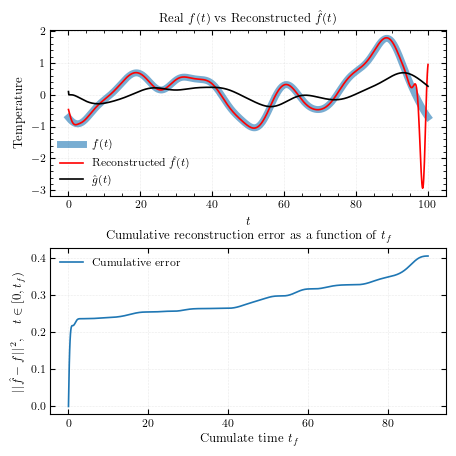

In [5]:
# Testing reconstruction with error measurement in frequencies

f = f_generator.generate_from_white_noise(42)
g = solver.solve(f)[solver.nx-1,:]

freq_amplifier = 1.01
freq_shift = 0.1

if freq_amplifier != 1 or freq_shift != 0:
    n = (2*solver.nt - 1)
    G = np.fft.rfft(g, n)
    G *= freq_amplifier
    G += freq_shift
    g = np.fft.irfft(G, n)[:solver.nt] 

f_reconstructed = th.regularize(g, lambda_reg=1e-2, regularization_type_="closed", maxiter=100)

_, _ ,_ = reconstruction_error_plot(f,g,f_reconstructed,solver.t_array, 100)

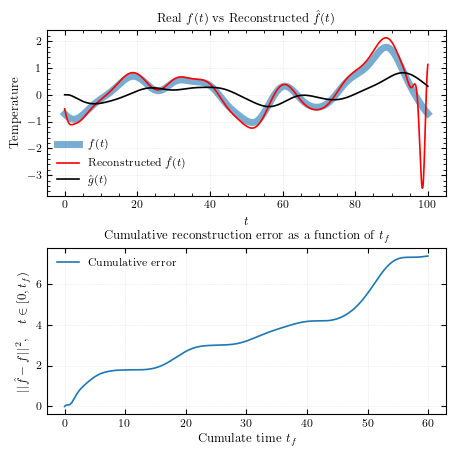

In [6]:
# Testing reconstruction with sensor amplification error

f = f_generator.generate_from_white_noise(42)
g = solver.solve(f)[solver.nx-1,:]
g *= 1.2

f_reconstructed = th.regularize(g, lambda_reg=1e-2, regularization_type_="closed", maxiter=100)

_, _ ,_ = reconstruction_error_plot(f,g,f_reconstructed,solver.t_array, 400)

## Test al variare della correlazione temporale

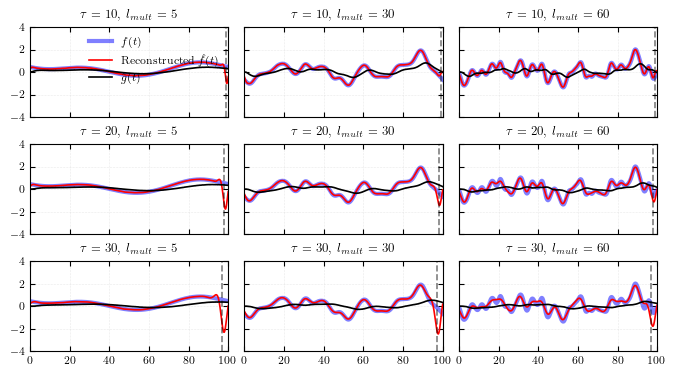

In [8]:
f_generator = FunctionsGenerator(solver.t_array, l=1)

max_frequency = 1/solver.dt
min_frequency = 1/Tf

# tau, n_eff = solver.diffusion_time()
loss_array = np.zeros(solver.nt)

time_correlation_multiplier_array = [5,30,60]
taus = [10, 20, 30]

n_corr = np.size(time_correlation_multiplier_array)
n_taus = np.size(taus)

errors_array_mean = np.zeros(shape=(n_taus,n_corr))
errors_array_var = np.zeros(shape=(n_taus,n_corr))

fig, axes = plt.subplots(n_taus, n_corr, figsize=(2.2*n_corr, 1.2*n_taus),sharex=True, sharey=True)

i = 0
for tau in taus:
    j = 0     
    
    # Fisso Tau ed L
    tmp_d = (L*L)/(tau)
    prop_time = (L*L)/tmp_d/(np.pi**2) # Tempo di propaazione del primo modo
    
    solver = Heat1DCrankNicolson(L,Tf,nt,tmp_d,h,wanted_r=wanted_r)
    th = TikhonovHandler(solver)
    
    impulse_response = solver.impulse_response()[-1]
    
    axes[0][0].set_ylim([-4,4])
    axes[0][0].set_xlim([0,Tf])
    
    for time_correlation_multiplier in time_correlation_multiplier_array:
        
        np.random.seed(42) # Reset seed
        f_generator.l = solver.Tf/time_correlation_multiplier
        
        if 1/f_generator.l > max_frequency/2:
            raise ValueError("The generated signal contains frequency that can not be sampled with the given dt")
        
        f = f_generator.generate_from_white_noise()
        
        g_target = solver.solve_from_impulse_response(f, impulse_response) + np.random.uniform(low=0, high=1,size=solver.nt)*0.01
        
        f_reconstructed = th.regularize(g_target, lambda_reg=1e-1, regularization_type_="closed")
        
        loss_array = np.zeros(solver.nt)
        
        for n in range(solver.nt):
            loss_array[n] = (f[n] - f_reconstructed[n])**2

        # Plot reconstruction
        axes[i][j].plot(solver.t_array, f, label=r"$f(t)$", lw=3, c="b", alpha =0.5)
        axes[i][j].plot(solver.t_array, f_reconstructed, label=r"Reconstructed $\hat{f}(t)$", c="r")
        axes[i][j].plot(solver.t_array, g_target, label=r"$\hat{g}(t)$", c="k")
        axes[i][j].axvline(solver.Tf-prop_time, c= "k", ls="--", alpha=0.5)
        
        axes[i][j].set_title(fr"$\tau$ = {tau:.0f}, $l_{{mult}}$ = {time_correlation_multiplier:.0f}")
        
        if i == 0 and j == 0:
            axes[i][j].legend()
        axes[i][j].grid()
        
        errors_array_mean[i][j] = (
            np.mean(loss_array) /
            np.mean(f**2)
        )
        errors_array_var[i][j] = np.var(loss_array)
        
        j = j + 1
         
    i = i + 1
   
plt.savefig("../assets/griglia_ricostruzioni.pdf")
plt.show()